# How a phase diagram is built: Mg–Ca

landau finds phase transitions by comparing the free energies of all phases. This notebook shows that in three steps:

- **a)** At 800 K, plot the semigrand potential $\phi$ of each phase against the chemical potential difference $\Delta\mu$. The phase with the lowest $\phi$ is stable, and transitions sit where the curves cross.
- **b)** The same temperature as free energy against concentration. The crossings from a) are now common tangents.
- **c)** Repeat over a range of temperatures to get the full phase diagram. The markers show the 800, 900 and 1000 K transitions.

The free energies in `MgCaFreeEnergies.pckl.gz` come from calphy calculations with an ACE potential.

Saves the figure as `MgCa_Phasediagram_Construction_landau.svg` and `.png`.

## Setup

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import landau as ld

warnings.simplefilter("ignore", DeprecationWarning)

In [2]:
DATA = "MgCaFreeEnergies.pckl.gz"
OUT = "MgCa_Phasediagram_Construction_landau.svg"

T_SLICE = 800  # temperature of panels a) and b)
T_CUTS = [800, 900, 1000]  # transitions marked in c)
T_RANGE = (700, 1100)
MU_RANGE = (-1.1, -0.1)
LIQ = "liquid"

FIGSIZE = (10.5, 7.5)
FONTSIZE = 15
DPI = 300

## Phases

The solids are line phases with a fixed composition. The liquid interpolates between free energies at several compositions. `fcc Ca` is not stable in this temperature range, so we leave it out.

In [3]:
raw = pd.read_pickle(DATA)
raw = raw[raw.phase != "fcc Ca"]


def line(r):
    return ld.phases.TemperatureDependentLinePhase(
        r.phase, r.composition, r.temperature, r.free_energy, interpolator=ld.interpolate.SGTE(4)
    )


solids = [line(r) for _, r in raw[raw.phase != LIQ].iterrows()]
liquid = ld.phases.FastInterpolatingPhase(LIQ, [line(r) for _, r in raw[raw.phase == LIQ].iterrows()])
phases = {p.name: p for p in solids + [liquid]}
phases

{'hcp Mg': TemperatureDependentLinePhase(name='hcp Mg', fixed_concentration=0.0, temperatures=array([ 300.        ,  300.00420006,  300.00840024, ...,  999.90667538,
         999.95333551, 1000.        ], shape=(50001,)), free_energies=array([-1.52251546, -1.52251687, -1.52251828, ..., -1.89900584,
        -1.89903773, -1.89906963], shape=(50001,)), interpolator=SGTE(nparam=4)),
 'bcc Ca': TemperatureDependentLinePhase(name='bcc Ca', fixed_concentration=1.0, temperatures=array([ 300.        ,  300.00461546,  300.00923106, ..., 1299.82798938,
        1299.91463891, 1300.0013    ], shape=(50001,)), free_energies=array([-1.93428445, -1.93428657, -1.93428869, ..., -2.64088933,
        -2.64096458, -2.64103983], shape=(50001,)), interpolator=SGTE(nparam=4)),
 'Mg$_2$Ca': TemperatureDependentLinePhase(name='Mg$_2$Ca', fixed_concentration=0.3333333333333333, temperatures=array([ 300.        ,  300.00420006,  300.00840024, ...,  999.90667538,
         999.95333551, 1000.        ], shape=(50001

## Calculate

One calculation per panel: a fine $\Delta\mu$ scan and a coarser scan at 800 K, then the full temperature range, then the three marked temperatures.

In [4]:
df_phi = ld.calculate.calc_phase_diagram(
    phases.values(), Ts=[T_SLICE], mu=np.linspace(*MU_RANGE, 200), keep_unstable=True
)
df_f = ld.calculate.calc_phase_diagram(phases.values(), Ts=[T_SLICE], mu=200, keep_unstable=True)
df_full = ld.calculate.calc_phase_diagram(phases.values(), Ts=np.linspace(*T_RANGE, 50), mu=200)
df_cuts = pd.concat(
    [ld.calculate.calc_phase_diagram(phases.values(), Ts=[T], mu=200) for T in T_CUTS], ignore_index=True
)

In [5]:
def transitions(df, T):
    """Coexisting phase rows at exactly temperature T, one group per mu."""
    b = df.query("locus == 'boundary' and T == @T").sort_values(["mu", "c"])
    return [g for _, g in b.groupby("mu")]


pd.concat([g for T in T_CUTS for g in transitions(df_cuts, T)])[["T", "phase", "mu", "c"]]

,T,phase,mu,c
200,800,hcp Mg,-0.901350,0.000000
201,800,liquid,-0.901350,0.062036
202,800,liquid,-0.769945,0.153952
203,800,Mg$_2$Ca,-0.769945,0.333333
204,800,Mg$_2$Ca,-0.383723,0.333333
205,800,liquid,-0.383723,0.544059
206,800,liquid,-0.219424,0.789715
207,800,bcc Ca,-0.219424,1.000000
408,900,liquid,-0.678721,0.243831
409,900,Mg$_2$Ca,-0.678721,0.333333


## Panels

In [6]:
def panel_phi(ax, df):
    ld.plot.plot_1d_mu_phase_diagram(
        df, ax=ax, ylim=(-2.1, -1.6), element="Ca", top_label_rotation="vertical", mark_transitions=False
    )
    for g in transitions(df, T_SLICE):
        ax.scatter(g.mu.iloc[0], g.phi.iloc[0], color="k", zorder=5)
    ax.set_xlabel(r"$\Delta\mu_\mathrm{Ca}$ [eV]")
    ax.set_ylabel(r"$\phi$ [eV/atom]")
    ax.set_title(f"T = {T_SLICE} K")


def panel_f(ax, df):
    plt.sca(ax)
    ld.plot.plot_excess_free_energy(df, element="Ca")
    for label in ax.texts:  # vertical, so they stay clear of the curves and axis
        label.set(rotation=90, rotation_mode="anchor")
    ax.set_xlabel(r"$c_\mathrm{Ca}$")
    ax.set_ylabel(r"$f_\mathrm{excess}$ [eV/atom]")
    ax.set_title(f"T = {T_SLICE} K")


def panel_diagram(ax, df_full, df_cuts):
    ld.plot.plot_phase_diagram(df_full, element="Ca", triplepoints=True, transition_temperatures=True, ax=ax)
    colors = ld.plot.get_phase_colors(df_full.phase.unique())
    for T in T_CUTS:
        for g in transitions(df_cuts, T):
            ax.scatter(g.c, [T] * len(g), color=[colors[p] for p in g.phase], s=45, edgecolor="k", lw=0.8, zorder=10, clip_on=False)

## Figure

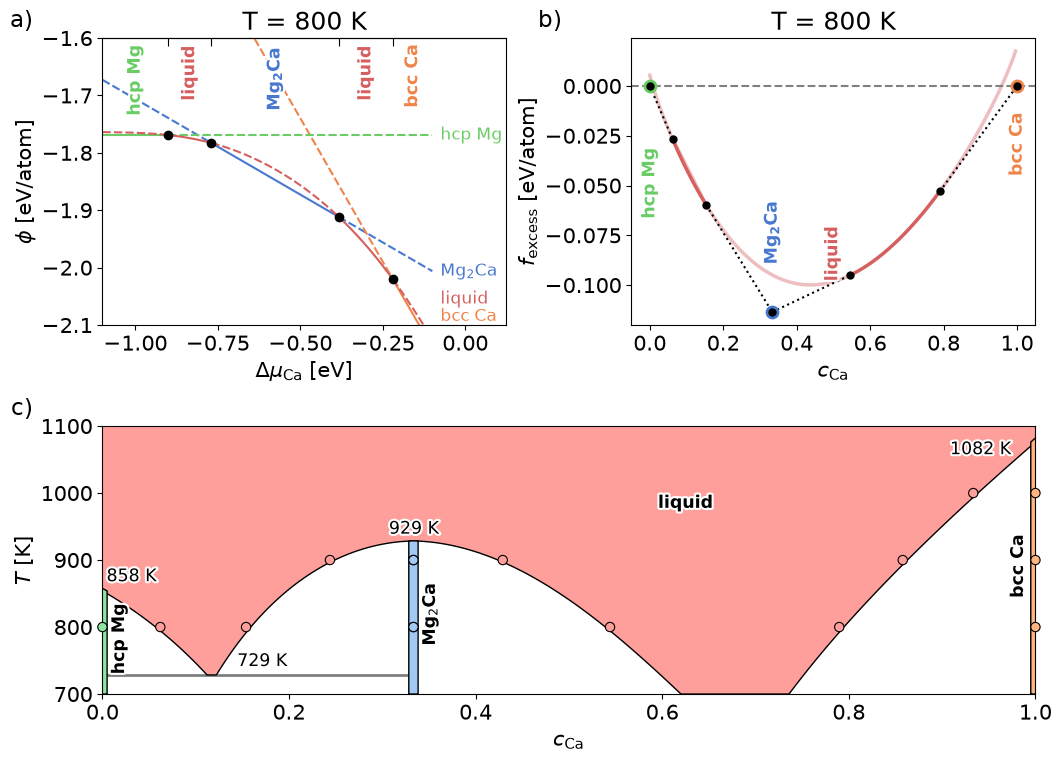

In [7]:
plt.rcParams.update({"font.size": FONTSIZE, "svg.fonttype": "none"})
fig = plt.figure(figsize=FIGSIZE)


def panel(left, top, right, bottom):
    """Axes with the given edges, in inches from the top left corner of the figure."""
    width, height = FIGSIZE
    return fig.add_axes((left / width, 1 - bottom / height, (right - left) / width, (bottom - top) / height))


ax_a = panel(0.96, 0.32, 5.0, 3.19)
ax_b = panel(6.25, 0.32, 10.29, 3.19)
ax_c = panel(0.96, 4.2, 10.29, 6.88)

panel_phi(ax_a, df_phi)
panel_f(ax_b, df_f)
panel_diagram(ax_c, df_full, df_cuts)

for ax, lab in zip((ax_a, ax_b, ax_c), "abc"):
    ax.annotate(f"{lab})", xy=(0, 1), xycoords="axes fraction", xytext=(-50, 4), textcoords="offset points",
                ha="right", va="bottom", fontsize=FONTSIZE + 1.5)

fig.savefig(OUT)
fig.savefig(OUT.replace(".svg", ".png"), dpi=DPI, transparent=True)